<a href="https://colab.research.google.com/github/JyRaGa/CS303-Machine-Learning_Coursework/blob/main/exp10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CS303 Machine Learning Lab
## Experiment No. 10: k-Means, Hierarchical Clustering and DBSCAN
### Roll No: 24/CS/232

---

### **Aim:**
To implement and compare **k-Means**, **Hierarchical Clustering**, and **DBSCAN** on spherical, non-spherical, and noisy datasets, and evaluate their performance using visualizations and silhouette scores.

### **Objectives:**
After completing this experiment, students will be able to:
1. Understand the fundamentals of **unsupervised learning** and **clustering**.
2. Implement **k-Means** clustering.
3. Implement **Agglomerative (Hierarchical) Clustering**.
4. Implement **DBSCAN** for density-based clustering.
5. **Compare** clustering algorithms on different cluster shapes.
6. Understand the effect of **feature scaling** on clustering results.
7. Evaluate clustering results using the **silhouette score**.
8. Identify how algorithms handle **noise and outliers**.
9. Understand the **limitations of k-Means** on non-spherical clusters.
10. **Recommend** a suitable clustering algorithm for different data distributions.

### **Pseudo Algorithm / Steps:**
1. **Start**
2. **Import** the required libraries.
3. **Generate** spherical, non-spherical, and noisy datasets.
4. **Visualize** the original datasets.
5. **Apply k-Means** to each dataset.
6. **Apply Agglomerative Clustering** to each dataset.
7. **Apply DBSCAN** to each dataset.
8. **Plot** the predicted cluster assignments for each algorithm.
9. **Repeat** clustering after standardizing features where appropriate.
10. **Calculate** silhouette scores for valid clustering results.
11. **Examine** the number of clusters and noise points detected.
12. **Compare** clustering quality and computational behavior.
13. **Recommend** the most suitable algorithm for each dataset type.
14. **Stop**

**1. Importing Libraries & Generating the Datasets (Steps 1–3)**

* **Unsupervised Learning:** clustering groups points by similarity **without using labels**. The true labels returned by the generators are kept aside only to check afterwards whether the found clusters match the real groups (Adjusted Rand Index, ARI).
* **Dataset 1 – Spherical:** `make_blobs()` with 3 compact, roughly spherical clusters (500 points).
* **Dataset 2 – Non-spherical:** `make_moons()` with 2 interleaving crescents (500 points, `noise=0.05`).
* **Dataset 3 – Noisy:** `make_blobs()` with 3 clusters plus 50 uniformly scattered **outlier points** (label `-1`).
* All generators use `random_state=42` so the results are reproducible.

In [ ]:
import time
import warnings
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.datasets import make_blobs, make_moons
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings('ignore')
X_sph, y_sph = make_blobs(n_samples=500, centers=3, cluster_std=0.8,
                          random_state=42)
X_moon, y_moon = make_moons(n_samples=500, noise=0.05, random_state=42)
X_blob, y_blob = make_blobs(n_samples=450, centers=3, cluster_std=0.8,
                            random_state=7)
rng = np.random.RandomState(42)
X_out = rng.uniform(X_blob.min(axis=0) - 3, X_blob.max(axis=0) + 3, size=(50, 2))
X_noisy = np.vstack([X_blob, X_out])
y_noisy = np.concatenate([y_blob, -np.ones(50, dtype=int)])  # -1 = outlier
datasets = {'Spherical': (X_sph, y_sph), 'Moons': (X_moon, y_moon),
            'Noisy': (X_noisy, y_noisy)}
for name, (X, y) in datasets.items():
    print(f'{name:10s}: shape {X.shape}, true groups = {len(set(y) - {-1})}, '
          f'outliers = {(y == -1).sum()}')

Spherical : shape (500, 2), true groups = 3, outliers = 0
Moons     : shape (500, 2), true groups = 2, outliers = 0
Noisy     : shape (500, 2), true groups = 3, outliers = 50


**2. Visualizing the Original Datasets (Step 4)**

* Each dataset is plotted with its **true** labels so we know what a good clustering should look like.
* Outliers in the noisy dataset are shown as grey crosses.

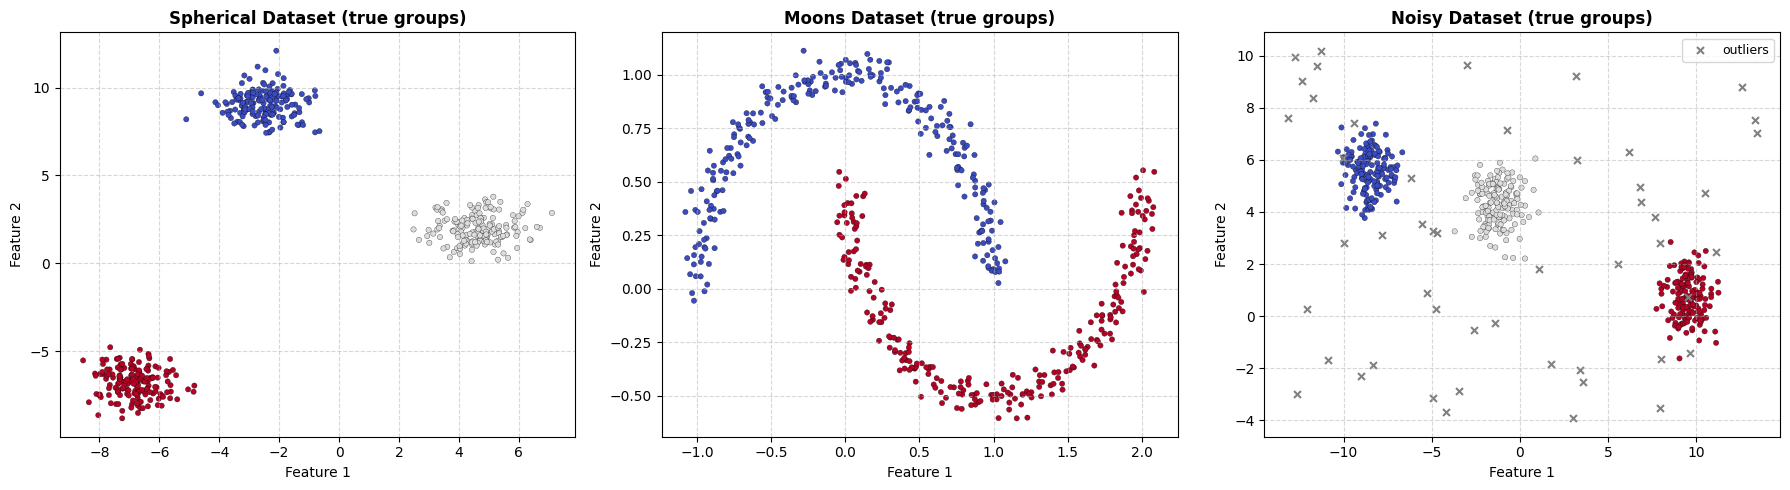

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, (X, y)) in zip(axes, datasets.items()):
    ax.scatter(X[y != -1, 0], X[y != -1, 1], c=y[y != -1], cmap='coolwarm', s=15,
               edgecolors='k', linewidths=0.2)
    if (y == -1).any():
        ax.scatter(X[y == -1, 0], X[y == -1, 1], c='grey', marker='x', s=25,
                   label='outliers')
        ax.legend(loc='upper right', fontsize=9)
    ax.set_title(f'{name} Dataset (true groups)', fontsize=12, fontweight='bold')
    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')
    ax.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**3. Applying k-Means to Each Dataset (Step 5)**

* **Objective (distortion function):** $J(c, \mu) = \sum_{i=1}^{n} \lVert x^{(i)} - \mu_{c^{(i)}} \rVert^2$, the sum of squared distances from each point to its assigned centroid (called **inertia** / WCSS in scikit-learn).
* **Algorithm:** repeat until the assignments stop changing: (1) **assign** each point to the closest centroid, $c^{(i)} = \arg\min_j \lVert x^{(i)} - \mu_j \rVert^2$; (2) **move** each centroid to the mean of its points. Each step can only lower $J$ (coordinate descent), so k-Means always converges, but only to a **local optimum**.
* **Initialization:** the classic method picks $k$ random training points as the starting centroids. Because $J$ is non-convex, a bad start can get stuck at a higher cost, so k-Means is run several times and the run with the lowest $J$ is kept (`n_init=10`). scikit-learn's default `init='k-means++'` picks the first centre at random and each next centre with probability proportional to its squared distance from the nearest chosen centre, so the starting centres are spread out.
* **Choosing $k$ (elbow method):** inertia (WCSS) always falls as $k$ grows; the "elbow", where adding a cluster stops helping much, suggests $k$. Here $k = 3$ for the spherical and noisy data and $k = 2$ for moons.
* Every point is forced into a cluster, so k-Means has **no notion of noise**.

Spherical : inertia =    611.62, iterations = 2, ari vs truth = 1.0000
Moons     : inertia =    202.42, iterations = 8, ari vs truth = 0.2525
Noisy     : inertia =   2046.35, iterations = 3, ari vs truth = 0.8431

=== RANDOM INIT vs K-MEANS++ (NOISY DATA, 20 SINGLE RUNS EACH) ===
random    : best =  2046.35, worst =  6416.55, runs stuck above best = 4
k-means++ : best =  2046.35, worst =  2046.35, runs stuck above best = 0


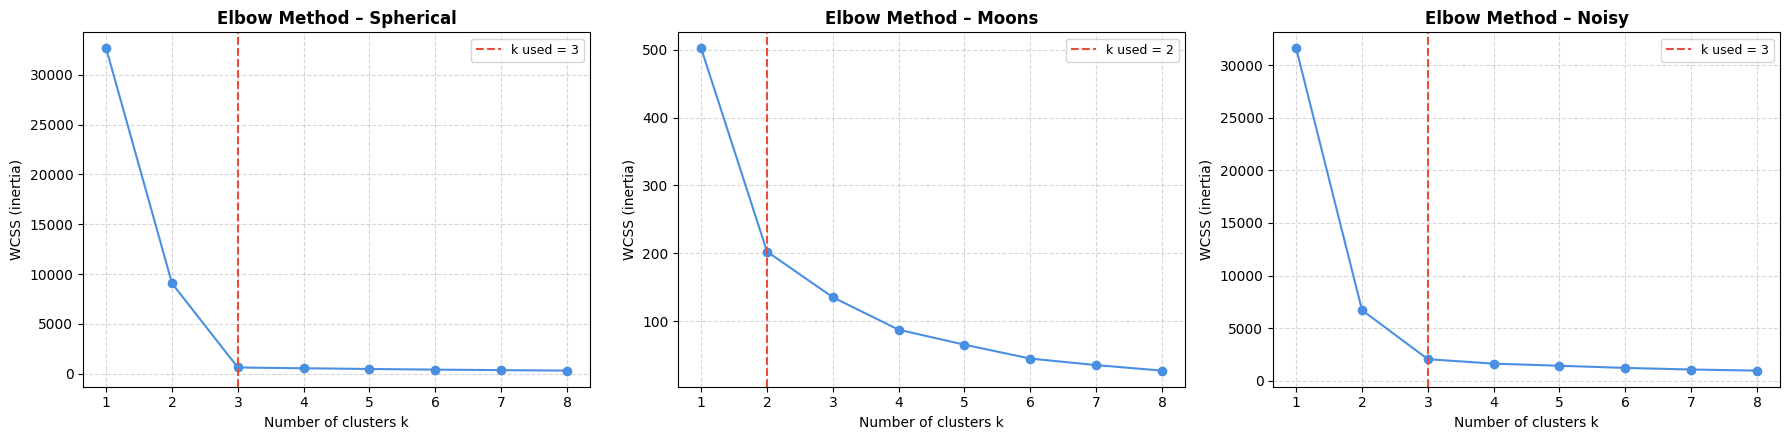

In [ ]:
n_clusters = {'Spherical': 3, 'Moons': 2, 'Noisy': 3}
labels, times = {}, {}  # (dataset, algorithm) -> labels / fit time
def run(name, algo, model, X):
    start = time.perf_counter()
    labels[(name, algo)] = model.fit_predict(X)
    times[(name, algo)] = time.perf_counter() - start
    return model
kmeans_models = {}
for name, (X, y) in datasets.items():
    km = run(name, 'k-Means',
             KMeans(n_clusters=n_clusters[name], n_init=10, random_state=42), X)
    kmeans_models[name] = km
    print(f'{name:10s}: inertia = {km.inertia_:9.2f}, iterations = {km.n_iter_}, '
          f'ari vs truth = {adjusted_rand_score(y, km.labels_):.4f}')
# single random-init runs can get stuck in a local optimum
print('\n=== RANDOM INIT vs K-MEANS++ (NOISY DATA, 20 SINGLE RUNS EACH) ===')
for init in ['random', 'k-means++']:
    costs = [KMeans(n_clusters=3, init=init, n_init=1, random_state=s).fit(X_noisy)
             .inertia_ for s in range(20)]
    print(f'{init:10s}: best = {min(costs):8.2f}, worst = {max(costs):8.2f}, '
          f'runs stuck above best = {sum(c > min(costs) + 1e-6 for c in costs)}')
# elbow method
ks = range(1, 9)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (name, (X, y)) in zip(axes, datasets.items()):
    wcss = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X).inertia_
            for k in ks]
    ax.plot(ks, wcss, marker='o', color='#4a90e2')
    ax.axvline(n_clusters[name], color='#e74c3c', linestyle='--',
               label=f'k used = {n_clusters[name]}')
    ax.set_title(f'Elbow Method – {name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Number of clusters k')
    ax.set_ylabel('WCSS (inertia)')
    ax.legend(fontsize=9)
    ax.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**4. Applying Agglomerative (Hierarchical) Clustering to Each Dataset (Step 6)**

* **Bottom-up:** every point starts as its own cluster and the two closest clusters are merged repeatedly until $k$ clusters remain.
* **Linkage** decides the distance between two clusters $K_i$ and $K_j$:
  * **Single:** $\min d(p, q)$ over $p \in K_i, q \in K_j$ (closest pair) — can form long, skinny clusters but chains through noise.
  * **Complete:** $\max d(p, q)$ (farthest pair) — gives tight, small, round clusters.
  * **Average:** mean of all pairwise distances — a compromise between the two, usually described as more robust to noise than single link.
  * **Ward** (scikit-learn default, used for the main results): merges the pair that gives the smallest increase in within-cluster variance, so like k-Means it prefers compact, round clusters.
* The **dendrogram** records the order and distance of every merge; cutting it where the vertical jump is largest suggests the number of clusters.
* All four linkages are compared on every dataset to see which one recovers the true groups.

Spherical : ari vs truth = 1.0000
Moons     : ari vs truth = 0.4035
Noisy     : ari vs truth = 0.8431

=== ARI vs TRUTH FOR EACH LINKAGE ===
  Dataset  Single  Complete  Average   Ward
Spherical  1.0000    1.0000   1.0000 1.0000
    Moons  1.0000    0.2527   0.1925 0.4035
    Noisy  0.0147    0.8430   0.4687 0.8431


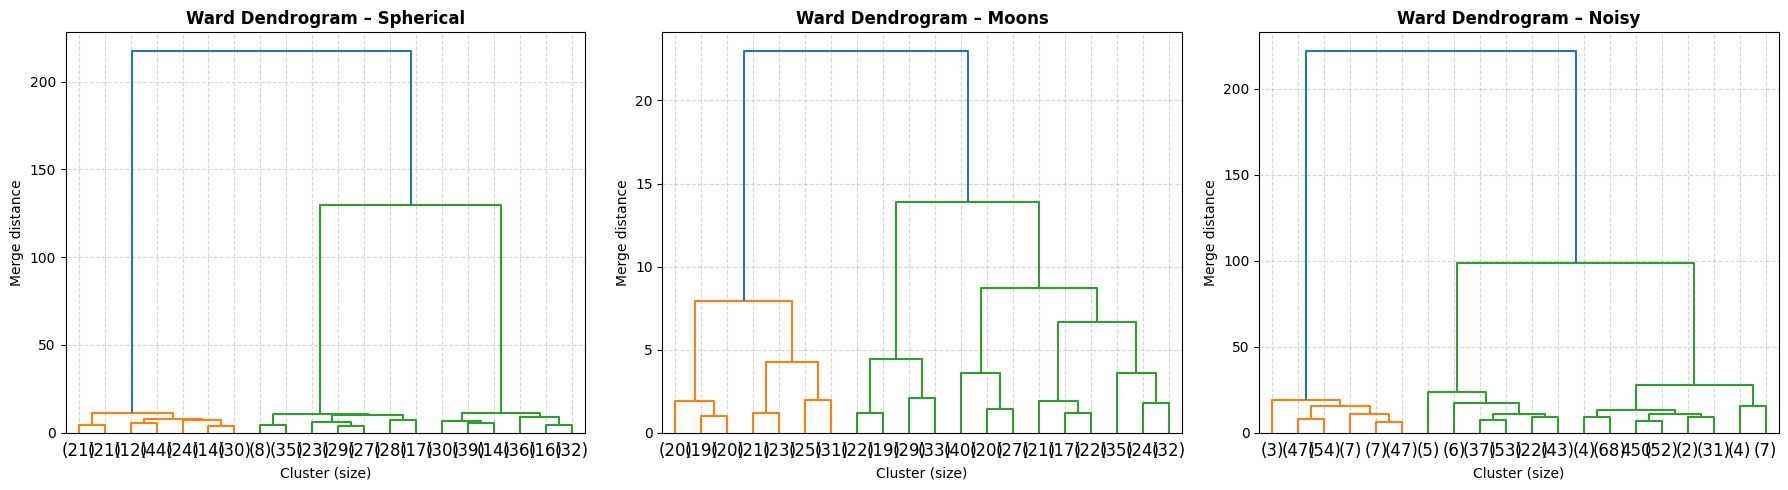

In [ ]:
for name, (X, y) in datasets.items():
    run(name, 'Hierarchical',
        AgglomerativeClustering(n_clusters=n_clusters[name], linkage='ward'), X)
    ari = adjusted_rand_score(y, labels[(name, 'Hierarchical')])
    print(f'{name:10s}: ari vs truth = {ari:.4f}')
link_rows = []
for name, (X, y) in datasets.items():
    row = {'Dataset': name}
    for link in ['single', 'complete', 'average', 'ward']:
        lab = AgglomerativeClustering(n_clusters=n_clusters[name],
                                      linkage=link).fit_predict(X)
        row[link.capitalize()] = adjusted_rand_score(y, lab)
    link_rows.append(row)
print('\n=== ARI vs TRUTH FOR EACH LINKAGE ===')
print(pd.DataFrame(link_rows).round(4).to_string(index=False))
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, (X, y)) in zip(axes, datasets.items()):
    dendrogram(linkage(X, method='ward'), ax=ax, truncate_mode='lastp', p=20,
               color_threshold=None)  # last 20 merges only
    ax.set_title(f'Ward Dendrogram – {name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Cluster (size)')
    ax.set_ylabel('Merge distance')
    ax.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**5. Applying DBSCAN to Each Dataset (Step 7)**

* **Density-based:** a point is a **core point** if at least `min_samples` points lie within radius `eps` of it. Core points that reach each other form a cluster, **border points** join a nearby core point, and everything else is labelled **noise** (`-1`).
* The number of clusters is **not** given; DBSCAN finds it from the density.
* **Choosing eps:** the distance from each point to its `min_samples`-th nearest neighbour shows the typical spacing of points in the data (its 90th percentile is printed). eps is set so that points inside a cluster connect but the gap between clusters is not bridged, and checked with the parameter sweep below. `min_samples = 5` is used for all datasets.
* A small sweep over eps and min_samples on the moons data shows how sensitive DBSCAN is to these two parameters.

In [ ]:
min_samples = 5
eps_values = {'Spherical': 0.6, 'Moons': 0.2, 'Noisy': 0.6}
for name, (X, y) in datasets.items():
    dist, _ = NearestNeighbors(n_neighbors=min_samples).fit(X).kneighbors(X)
    k_dist = np.sort(dist[:, -1])
    db = run(name, 'DBSCAN',
             DBSCAN(eps=eps_values[name], min_samples=min_samples), X)
    lab = db.labels_
    print(f'{name:10s}: 90th pct of {min_samples}-nn distance = '
          f'{np.percentile(k_dist, 90):.3f}, eps used = {eps_values[name]}, '
          f'clusters = {len(set(lab) - {-1})}, noise = {(lab == -1).sum()}, '
          f'ari = {adjusted_rand_score(y, lab):.4f}')
# effect of eps and min_samples on the moons data
sweep = []
for eps in [0.05, 0.1, 0.2, 0.3, 0.5]:
    for ms in [3, 5, 10]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_moon)
        sweep.append({'eps': eps, 'min_samples': ms,
                      'Clusters': len(set(lab) - {-1}),
                      'Noise points': (lab == -1).sum(),
                      'ARI vs truth': adjusted_rand_score(y_moon, lab)})
print('\n=== DBSCAN PARAMETER SWEEP (MOONS) ===')
print(pd.DataFrame(sweep).round(4).to_string(index=False))

Spherical : 90th pct of 5-nn distance = 0.484, eps used = 0.6, clusters = 3, noise = 14, ari = 0.9576
Moons     : 90th pct of 5-nn distance = 0.084, eps used = 0.2, clusters = 2, noise = 0, ari = 1.0000
Noisy     : 90th pct of 5-nn distance = 1.025, eps used = 0.6, clusters = 3, noise = 62, ari = 0.9367

=== DBSCAN PARAMETER SWEEP (MOONS) ===
 eps  min_samples  Clusters  Noise points  ARI vs truth
0.05            3        40            75        0.0470
0.05            5        38           194        0.0247
0.05           10         1           489        0.0018
0.10            3         2             4        0.9841
0.10            5         2             7        0.9722
0.10           10         4            13        0.6745
0.20            3         2             0        1.0000
0.20            5         2             0        1.0000
0.20           10         2             0        1.0000
0.30            3         2             0        1.0000
0.30            5         2            

**6. Plotting the Predicted Cluster Assignments (Step 8)**

* A $3 \times 3$ grid: rows are the datasets, columns are the algorithms.
* DBSCAN noise points are drawn as grey crosses; k-Means centroids are drawn as black stars.
* Each panel title shows the ARI against the true groups, so the picture and the number can be read together.

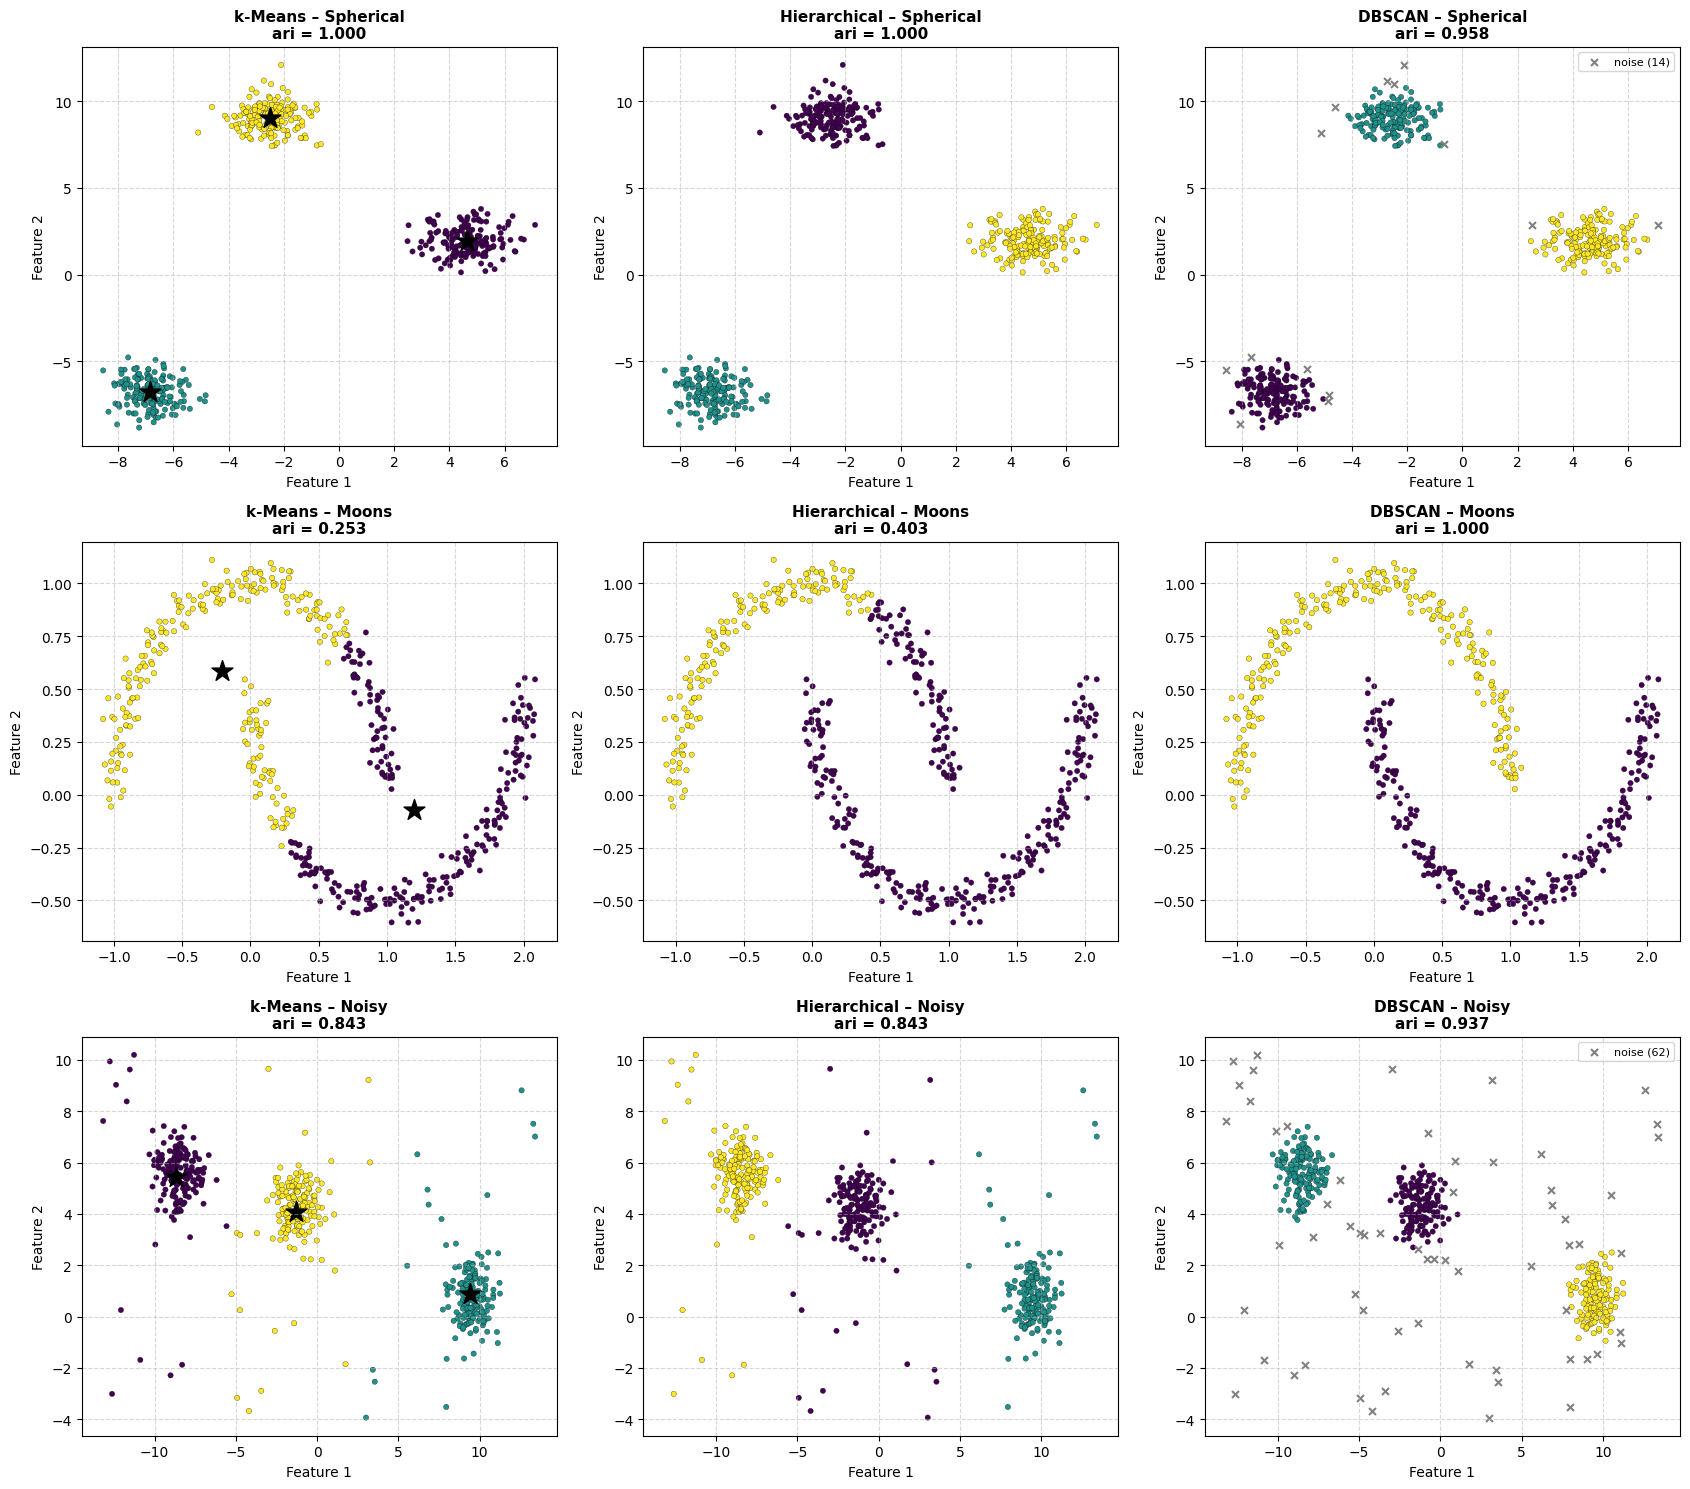

In [ ]:
algos = ['k-Means', 'Hierarchical', 'DBSCAN']
def plot_clusters(ax, X, lab, title):
    ax.scatter(X[lab != -1, 0], X[lab != -1, 1], c=lab[lab != -1], cmap='viridis',
               s=15, edgecolors='k', linewidths=0.2)
    if (lab == -1).any():
        ax.scatter(X[lab == -1, 0], X[lab == -1, 1], c='grey', marker='x', s=25,
                   label=f'noise ({(lab == -1).sum()})')
        ax.legend(loc='upper right', fontsize=8)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('Feature 1')
    ax.set_ylabel('Feature 2')
    ax.grid(linestyle='--', alpha=0.5)
fig, axes = plt.subplots(3, 3, figsize=(17, 15))
for i, (name, (X, y)) in enumerate(datasets.items()):
    for j, algo in enumerate(algos):
        lab = labels[(name, algo)]
        title = f'{algo} – {name}\nari = {adjusted_rand_score(y, lab):.3f}'
        plot_clusters(axes[i, j], X, lab, title)
        if algo == 'k-Means':
            c = kmeans_models[name].cluster_centers_
            axes[i, j].scatter(c[:, 0], c[:, 1], c='black', marker='*', s=250,
                               label='centroids')
plt.tight_layout()
plt.show()

**7. Repeating Clustering After Standardizing Features (Step 9)**

* All three algorithms depend on **Euclidean distance**, so a feature with a larger range dominates the distance.
* Here the two features already have similar ranges, so to make the effect visible the **second feature is multiplied by 10** (e.g. a feature measured in mm instead of cm). We then cluster the stretched data **without** and **with** `StandardScaler` (zero mean, unit variance).
* The DBSCAN `eps` cannot be reused across scales, so on standardized data it is chosen again from the k-distance curve (90th percentile).
* Clusters are compared with the true groups using ARI; the higher the ARI, the better the true clusters were recovered.

In [ ]:
scale_rows = []
scaled_data = {}
for name, (X, y) in datasets.items():
    X_str = X * np.array([1, 10])  # second feature on a 10x bigger scale
    X_std = StandardScaler().fit_transform(X_str)
    scaled_data[name] = X_std
    for version, Xv in [('Stretched (raw)', X_str), ('Standardized', X_std)]:
        dist, _ = NearestNeighbors(n_neighbors=min_samples).fit(Xv).kneighbors(Xv)
        eps = np.percentile(dist[:, -1], 90)  # eps from k-distance for this scale
        k = n_clusters[name]
        models = {'k-Means': KMeans(n_clusters=k, n_init=10, random_state=42),
                  'Hierarchical': AgglomerativeClustering(n_clusters=k),
                  'DBSCAN': DBSCAN(eps=eps, min_samples=min_samples)}
        for algo, model in models.items():
            lab = model.fit_predict(Xv)
            ari = adjusted_rand_score(y, lab)
            scale_rows.append({'Dataset': name, 'Features': version,
                               'Algorithm': algo, 'ARI vs truth': ari})
df_scale = pd.DataFrame(scale_rows).pivot_table(
    index=['Dataset', 'Algorithm'], columns='Features',
    values='ARI vs truth', sort=False)
df_scale = df_scale[['Stretched (raw)', 'Standardized']].reset_index()
df_scale['Change'] = df_scale['Standardized'] - df_scale['Stretched (raw)']
print('=== EFFECT OF FEATURE SCALING (ARI vs TRUE GROUPS) ===')
print(df_scale.round(4).to_string(index=False))

=== EFFECT OF FEATURE SCALING (ARI vs TRUE GROUPS) ===
  Dataset    Algorithm  Stretched (raw)  Standardized  Change
Spherical      k-Means           1.0000        1.0000  0.0000
Spherical Hierarchical           1.0000        1.0000  0.0000
Spherical       DBSCAN           0.8854        0.9168  0.0314
    Moons      k-Means           0.4505        0.4451 -0.0054
    Moons Hierarchical           0.2992        0.6587  0.3595
    Moons       DBSCAN           0.2798        0.7698  0.4900
    Noisy      k-Means           0.5853        0.8435  0.2582
    Noisy Hierarchical           0.5195        0.8437  0.3242
    Noisy       DBSCAN           0.5741        0.9616  0.3876


**8. Silhouette Scores, Number of Clusters & Noise Points – Observation Table (Steps 10–11)**

* **Silhouette score** of a point: $s(i) = \dfrac{b(i) - a(i)}{\max\{a(i), b(i)\}}$, where $a(i)$ is the mean distance to points in its own cluster and $b(i)$ the mean distance to the nearest other cluster. The overall score is the mean of $s(i)$, from $-1$ to $1$.
* **Valid results only:** the silhouette needs at least 2 clusters. For DBSCAN it is computed on the non-noise points, since noise is not a cluster.
* **Columns** follow the observation table in the lab PDF (Dataset, Algorithm, Number of clusters, Noise points, Silhouette score), plus ARI vs the true groups, because a high silhouette does not prove that the right shape was found.

In [ ]:
def valid_silhouette(X, lab):
    mask = lab != -1
    if len(set(lab[mask])) < 2:
        return np.nan  # silhouette not defined for one cluster
    return silhouette_score(X[mask], lab[mask])
rows = []
for name, (X, y) in datasets.items():
    for algo in algos:
        lab = labels[(name, algo)]
        rows.append({'Dataset': name, 'Algorithm': algo,
                     'Number of clusters': len(set(lab) - {-1}),
                     'Noise points': (lab == -1).sum(),
                     'Silhouette score': valid_silhouette(X, lab),
                     'ARI vs truth': adjusted_rand_score(y, lab),
                     'Fit time (ms)': times[(name, algo)] * 1000})
df_obs = pd.DataFrame(rows)
print('=== OBSERVATION TABLE ===')
print(df_obs.drop(columns='Fit time (ms)').round(4).to_string(index=False))

=== OBSERVATION TABLE ===
  Dataset    Algorithm  Number of clusters  Noise points  Silhouette score  ARI vs truth
Spherical      k-Means                   3             0            0.8751        1.0000
Spherical Hierarchical                   3             0            0.8751        1.0000
Spherical       DBSCAN                   3            14            0.8801        0.9576
    Moons      k-Means                   2             0            0.4888        0.2525
    Moons Hierarchical                   2             0            0.4472        0.4035
    Moons       DBSCAN                   2             0            0.3341        1.0000
    Noisy      k-Means                   3             0            0.7566        0.8431
    Noisy Hierarchical                   3             0            0.7532        0.8431
    Noisy       DBSCAN                   3            62            0.8421        0.9367


**9. Comparing Clustering Quality & Computational Behavior (Step 12)**

* **Quality:** silhouette score (internal, uses only the data) is compared side by side with ARI (external, uses the true groups).
* **Computation:** fit times are measured with `time.perf_counter()`. k-Means costs $O(n \cdot k \cdot d \cdot i)$ for $n$ points, $k$ clusters, $d$ features and $i$ iterations. Naive agglomerative clustering does $n$ merges and recomputes up to $n^2$ distances each time, i.e. $O(n^3)$ (library versions are faster but still need $O(n^2)$ memory). DBSCAN with a tree index is about $O(n \log n)$.
* To see how this scales, each algorithm is also timed on bigger blob datasets.
* *Note: fit times depend on the machine and change slightly between runs.*

=== FIT TIME (s) vs DATASET SIZE ===
Algorithm  k-Means  Hierarchical  DBSCAN
Samples                                 
1000        0.0164        0.0459  0.0187
2000        0.0453        0.3303  0.0544
4000        0.0271        2.0336  0.1112
8000        0.1160        8.2413  0.5059


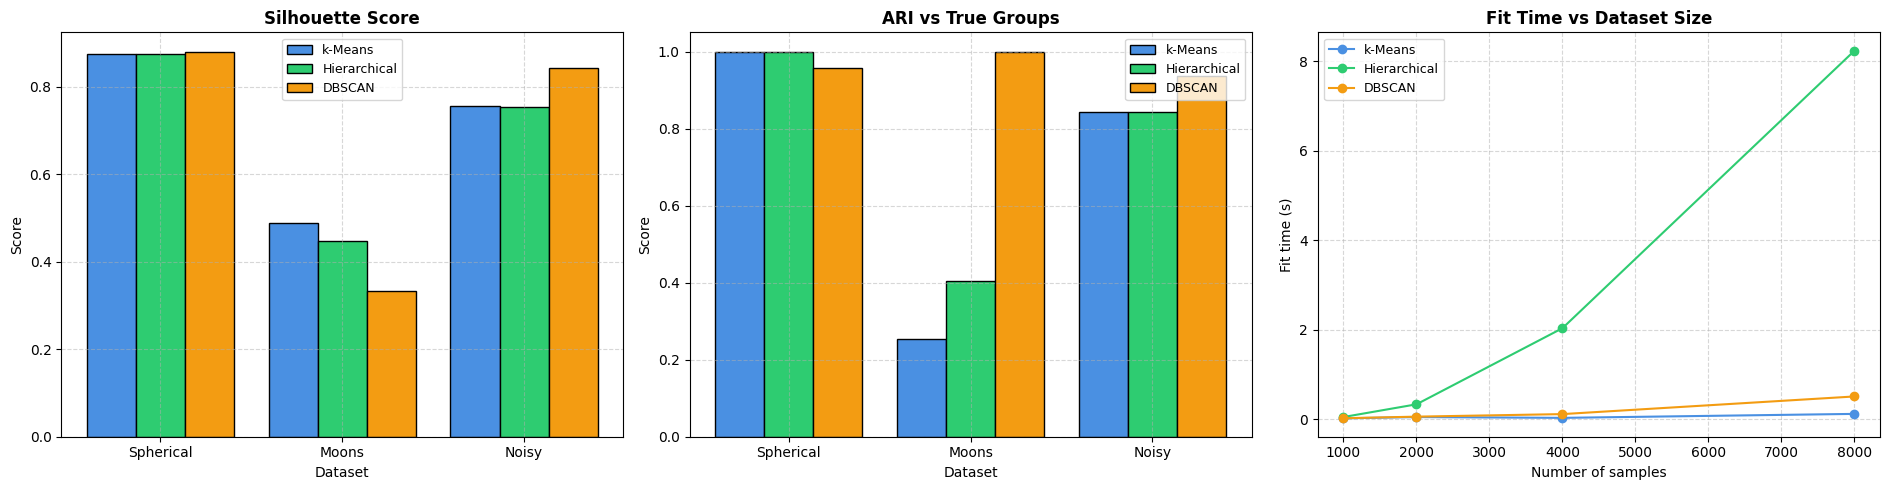

In [ ]:
size_rows = []
for n in [1000, 2000, 4000, 8000]:
    Xn, _ = make_blobs(n_samples=n, centers=3, cluster_std=0.8, random_state=42)
    for algo, m in [('k-Means', KMeans(n_clusters=3, n_init=10, random_state=42)),
                    ('Hierarchical', AgglomerativeClustering(n_clusters=3)),
                    ('DBSCAN', DBSCAN(eps=0.6, min_samples=5))]:
        start = time.perf_counter()
        m.fit(Xn)
        size_rows.append({'Samples': n, 'Algorithm': algo,
                          'Fit time (s)': time.perf_counter() - start})
df_size = pd.DataFrame(size_rows).pivot(index='Samples', columns='Algorithm',
                                        values='Fit time (s)')[algos]
print('=== FIT TIME (s) vs DATASET SIZE ===')
print(df_size.round(4).to_string())
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
colors = ['#4a90e2', '#2ecc71', '#f39c12']
x = np.arange(len(datasets))
for j, algo in enumerate(algos):
    d = df_obs[df_obs['Algorithm'] == algo]
    axes[0].bar(x + (j - 1) * 0.27, d['Silhouette score'], 0.27, label=algo,
                color=colors[j], edgecolor='black')
    axes[1].bar(x + (j - 1) * 0.27, d['ARI vs truth'], 0.27, label=algo,
                color=colors[j], edgecolor='black')
    axes[2].plot(df_size.index, df_size[algo], marker='o', label=algo,
                 color=colors[j])
for ax, title in zip(axes[:2], ['Silhouette Score', 'ARI vs True Groups']):
    ax.set_xticks(x)
    ax.set_xticklabels(datasets.keys())
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Dataset')
    ax.set_ylabel('Score')
axes[2].set_title('Fit Time vs Dataset Size', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Number of samples')
axes[2].set_ylabel('Fit time (s)')
for ax in axes:
    ax.legend(fontsize=9)
    ax.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**10. Recommending the Most Suitable Algorithm for Each Dataset (Step 13)**

* The silhouette score can favour the wrong answer (e.g. convex clusters cut through the moons), so the recommendation uses **ARI with the true groups first**, and the silhouette score only to break ties.
* The recommendation is printed together with the reason taken from the numbers above.

In [ ]:
recommend = {}
for name in datasets:
    d = df_obs[df_obs['Dataset'] == name]
    d = d.sort_values(['ARI vs truth', 'Silhouette score'], ascending=False)
    best = d.iloc[0]
    recommend[name] = best['Algorithm']
    print(f"{name:10s} -> {best['Algorithm']:12s} "
          f"(ari = {best['ARI vs truth']:.4f}, "
          f"silhouette = {best['Silhouette score']:.4f}, "
          f"clusters = {best['Number of clusters']}, "
          f"noise = {best['Noise points']})")

Spherical  -> k-Means      (ari = 1.0000, silhouette = 0.8751, clusters = 3, noise = 0)
Moons      -> DBSCAN       (ari = 1.0000, silhouette = 0.3341, clusters = 2, noise = 0)
Noisy      -> DBSCAN       (ari = 0.9367, silhouette = 0.8421, clusters = 3, noise = 62)


**11. Outcome & Observations (Steps 10–13)**

### **Observation Table (Recorded Output):**

| Dataset | Algorithm | Number of clusters | Noise points | Silhouette score | ARI vs truth |
| :--- | :--- | :---: | :---: | :---: | :---: |
| **Spherical** | k-Means | 3 | 0 | 0.8751 | 1.0000 |
| **Spherical** | Hierarchical | 3 | 0 | 0.8751 | 1.0000 |
| **Spherical** | DBSCAN | 3 | 14 | 0.8801 | 0.9576 |
| **Moons** | k-Means | 2 | 0 | 0.4888 | 0.2525 |
| **Moons** | Hierarchical | 2 | 0 | 0.4472 | 0.4035 |
| **Moons** | DBSCAN | 2 | 0 | 0.3341 | 1.0000 |
| **Noisy** | k-Means | 3 | 0 | 0.7566 | 0.8431 |
| **Noisy** | Hierarchical | 3 | 0 | 0.7532 | 0.8431 |
| **Noisy** | DBSCAN | 3 | 62 | 0.8421 | 0.9367 |

*Note: the DBSCAN silhouette is computed without its noise points. Fit times (Section 9) depend on the machine and change slightly between runs.*

---

### **Observations:**
* **All Three Algorithms Work:** k-Means, Agglomerative clustering and DBSCAN were applied to all three datasets and each found the expected number of clusters (3, 2, 3) with the parameters used.
* **k-Means on Spherical Clusters:** k-Means recovered the three blobs perfectly (ARI = 1.0000, silhouette = 0.8751) in only 2 iterations, because compact round clusters are exactly what the nearest-centroid rule assumes.
* **Initialization Matters:** In 20 single runs on the noisy data, random initialization got stuck in a worse local optimum 4 times (distortion up to 6416.55 vs the best 2046.35), while k-means++ reached the best value in all 20 runs.
* **Elbow Method:** The WCSS curve bends sharply at $k = 3$ for the spherical and noisy data, matching the true number of groups. For the moons there is no clear elbow, because the crescents are not compact groups.
* **Limitation of Centroid-Based Clustering:** On the moons, k-Means cut both crescents with a straight boundary (ARI = 0.2525), and Ward hierarchical clustering did only a little better (ARI = 0.4035).
* **Effect of Linkage:** Single linkage followed the crescents and recovered the moons perfectly (ARI = 1.0000), but on the noisy data it chained through the outliers and collapsed (ARI = 0.0147). Complete (0.8430) and Ward (0.8431) were the most robust there, while average linkage reached 0.4687.
* **Silhouette Can Mislead:** On the moons, k-Means had the **highest** silhouette (0.4888) but the **lowest** ARI, while DBSCAN had the lowest silhouette (0.3341) but recovered both crescents exactly (ARI = 1.0000). The silhouette rewards round, well-separated groups, not the true shape.
* **DBSCAN and Noise:** On the noisy data DBSCAN flagged 62 points as noise (50 outliers were added) and reached the best ARI (0.9367), while k-Means and hierarchical clustering forced every outlier into a cluster (ARI = 0.8431).
* **Influence of eps and min_samples:** On the moons, eps = 0.05 broke the data into 38–40 fragments, eps = 0.2–0.3 gave the correct 2 clusters for every min_samples, and eps = 0.5 merged everything into 1 cluster. At eps = 0.1, raising min_samples from 3 to 10 increased noise points from 4 to 13.
* **Influence of Feature Scaling:** After stretching the second feature by 10×, standardizing raised the ARI of DBSCAN from 0.2798 to 0.7698 on the moons and from 0.5741 to 0.9616 on the noisy data; for the well-separated spherical blobs k-Means and hierarchical clustering were unaffected (ARI = 1.0000 either way).
* **Computational Behavior:** Going from 1,000 to 8,000 samples, the hierarchical fit time grew about 180× (0.05 s → 8.24 s), while k-Means stayed under 0.05 s and DBSCAN under 0.6 s.

### **Conclusion:**
* **Spherical Data → k-Means:** k-Means and Ward hierarchical clustering both gave a perfect result (ARI = 1.0000, silhouette = 0.8751), but k-Means is recommended because it is much faster on large data and can assign new points with `predict()`.
* **Non-spherical (Moons) Data → DBSCAN:** With eps = 0.2 and min_samples = 5, DBSCAN recovered both crescents exactly (ARI = 1.0000), whereas k-Means (0.2525) and Ward hierarchical clustering (0.4035) failed despite higher silhouette scores. Single-linkage hierarchical clustering also recovered the moons, but it breaks down as soon as noise is present (ARI = 0.0147 on the noisy data), so DBSCAN is the safer choice. Plots must be checked along with the silhouette.
* **Noisy Data → DBSCAN:** DBSCAN marked 62 points as noise and gave the best agreement with the true groups (ARI = 0.9367, silhouette = 0.8421), while the other two algorithms had no way to reject outliers.
* **Scaling and Parameters:** All three methods are distance-based, so features must be standardized when their ranges differ (DBSCAN on stretched moons: ARI 0.2798 → 0.7698). DBSCAN additionally needs a well-chosen eps; too small fragments the data and too large merges it.
* **Final Recommendation:** No single algorithm is best for all data: use **k-Means** for compact spherical clusters, and **DBSCAN** for irregular shapes or data with noise, as long as the clusters have similar density.

In [ ]:
best_model = kmeans_models['Spherical']  # only k-means has predict() for new points
joblib.dump(best_model, 'kmeans_spherical_model.pkl')
loaded_model = joblib.load('kmeans_spherical_model.pkl')
same = (loaded_model.predict(X_sph) == labels[('Spherical', 'k-Means')]).all()
print('model saved and reloaded, same labels:', same)

model saved and reloaded, same labels: True


**12. Viva Questions & Comprehensive Answers**

### **Q1. What is clustering?**
**Answer:** Clustering is an **unsupervised learning** task that groups data points so that points in the same cluster are more similar to each other than to points in other clusters. No labels are used during training; the algorithm discovers the structure from the features alone. Common families are **centroid-based** (k-Means), **hierarchical** (Agglomerative) and **density-based** (DBSCAN). It is used for customer segmentation, image compression, anomaly detection and exploratory analysis.

---

### **Q2. What is the main objective of k-Means?**
**Answer:** k-Means partitions the data into $k$ clusters by minimising the **distortion** (within-cluster sum of squares) $J(c, \mu) = \sum_{i=1}^{n} \lVert x^{(i)} - \mu_{c^{(i)}} \rVert^2$. It repeatedly assigns each point to the nearest centroid and then moves each centroid to the mean of its points; this is **coordinate descent** on $J$, so $J$ never increases and the algorithm always converges, but only to a **local optimum**. That is why it is run with several initializations (or k-means++): in our test, random initialization got stuck at a worse cost in 4 of 20 runs. On the spherical dataset it converged in only 2 iterations to a perfect clustering (ARI = 1.0).

---

### **Q3. Why does k-Means struggle with moon-shaped clusters?**
**Answer:** k-Means works well only for **round, roughly equal size and density** clusters. It assigns each point to its **nearest centroid**, so the boundary between two clusters is always a straight line (a Voronoi cell), and every cluster is assumed to be convex. A crescent is neither, and the ends of one moon are closer to the other moon's centroid. In this experiment k-Means split the moons with a straight cut and reached only ARI = 0.25, even though its silhouette score (0.49) looked reasonable.

---

### **Q4. What is hierarchical clustering?**
**Answer:** Hierarchical clustering builds a **tree of nested clusters**. The **agglomerative** (bottom-up, AGNES) version starts with every point as its own cluster and repeatedly merges the closest pair; the **divisive** (top-down, DIANA) version splits instead. The distance between clusters is set by the **linkage**: **single** (closest pair, can form long skinny clusters), **complete** (farthest pair, tight round clusters), **average** (mean of all pairs) or **Ward** (smallest increase in variance). The merge history is drawn as a **dendrogram**, and cutting it at a chosen height gives the final clusters, so $k$ can be picked after clustering. In our run single linkage recovered the moons perfectly (ARI = 1.0) but collapsed on the noisy data (ARI = 0.01). The naive algorithm is $O(n^3)$, and its fit time grew from 0.05 s to 8.24 s between 1,000 and 8,000 samples above.

---

### **Q5. What is DBSCAN?**
**Answer:** **DBSCAN** (Density-Based Spatial Clustering of Applications with Noise) forms clusters from **dense regions** of points. A point with at least `min_samples` neighbours within distance `eps` is a **core point**; core points that are within `eps` of each other are joined into the same cluster, **border points** attach to a nearby core point, and all remaining points are marked as **noise** (label $-1$). Because clusters grow through chains of dense points, DBSCAN can find arbitrarily shaped clusters such as the two moons.

---

### **Q6. What do eps and min_samples mean in DBSCAN?**
**Answer:** `eps` is the **radius** of the neighbourhood around each point, and `min_samples` is the **minimum number of points** (including the point itself) that must be inside that radius for the point to be a core point. A small `eps` or large `min_samples` demands higher density, producing many small clusters and more noise; a large `eps` merges separate clusters. In the moons sweep, eps = 0.05 gave 38–40 fragments, eps = 0.2 gave the correct 2 clusters and eps = 0.5 merged everything into one. A k-distance plot is a common way to pick `eps`.

---

### **Q7. Does DBSCAN require the number of clusters in advance?**
**Answer:** **No.** The number of clusters is a result of the density parameters `eps` and `min_samples`, not an input. This is an advantage over k-Means and Agglomerative clustering, which need $k$ (or a cut height). However, the problem is moved to choosing `eps` well, and DBSCAN struggles when clusters have very **different densities**, since one `eps` cannot suit all of them.

---

### **Q8. Why is feature scaling important?**
**Answer:** k-Means, Agglomerative clustering and DBSCAN all rely on **Euclidean distance**, so a feature with a larger numeric range dominates the distance and the other features are effectively ignored. **Standardization** ($z = \frac{x - \mu}{\sigma}$) gives every feature equal weight. In Section 7, after one feature was stretched 10×, standardizing raised DBSCAN's ARI on the moons from 0.28 to 0.77 and on the noisy data from 0.57 to 0.96. It also makes a single `eps` value meaningful in every direction.

---

### **Q9. What is the silhouette score?**
**Answer:** For each point, $s(i) = \frac{b(i) - a(i)}{\max\{a(i), b(i)\}}$, where $a(i)$ is the mean distance to points in its own cluster and $b(i)$ is the mean distance to points in the nearest other cluster. The score is averaged over all points and ranges from $-1$ to $1$: near $1$ means compact, well-separated clusters, near $0$ means overlapping clusters, and negative values suggest wrong assignments. It is an **internal** validation measure (no true labels needed), unlike **external** measures such as purity or ARI that compare clusters with known classes. It favours convex clusters — on the moons, k-Means scored 0.49 while the correct DBSCAN solution scored only 0.33.

---

### **Q10. Which algorithm is best for all datasets?**
**Answer:** **None.** Each algorithm makes different assumptions about cluster shape and density (the "no free lunch" idea). In this experiment **k-Means** (and Ward hierarchical clustering) was best on the spherical blobs, while **DBSCAN** was best on the moons (ARI = 1.0) and on the noisy data (ARI = 0.94). The choice should be based on the expected shape, density, presence of noise and dataset size, and checked using both visualizations and scores.